In [1]:
import numpy as np
import torch
import matplotlib.pyplot as plt
from sklearn.decomposition import PCA
from torus_clock.model import load_model, capture

/home/bigburrito/icai/xai/torus-clock/.venv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [2]:
model = load_model()

Loading weights: 100%|██████████| 143/143 [00:00<00:00, 3130.29it/s]


## A - Let's see some circles

In [3]:
n = 300
T = 512
H = 64
noise = 3

In [4]:
rng = np.random.default_rng(0)
t = np.arange(T + H)
phi0 = rng.uniform(0, 2*np.pi, size=(n,1))
x = 10 + 3 * np.cos(2*np.pi*t/24 + phi0) + noise * rng.normal(size=(n, T + H))
context = torch.tensor(x[:, :T], dtype=torch.float32)
acts, out = capture(model, context)
q = out.quantile_preds

In [15]:
acts.keys()

dict_keys(['layer 0', 'layer 1', 'layer 2', 'layer 3', 'layer 4', 'layer 5', 'layer 6', 'encoder out'])

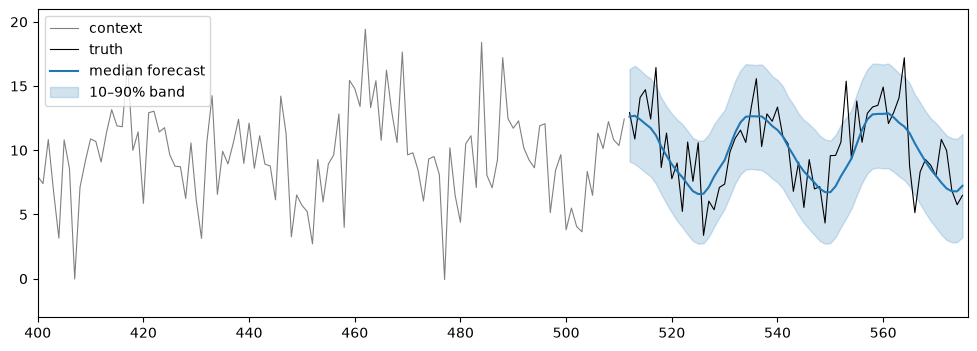

In [5]:
idx = 0

fig, ax = plt.subplots(figsize=(12, 4))
ax.plot(t[:T], x[idx, :T], color="gray", lw=0.8, label="context")
ax.plot(t[T:], x[idx, T:], color="black", lw=0.8, label="truth")
ax.plot(t[T:], q[idx, 4], color="C0", label="median forecast")
ax.fill_between(t[T:], q[idx, 0], q[idx, 8], color="C0", alpha=0.2, label="10–90% band")
ax.set_xlim(400, T + 64)
ax.legend()
plt.show()

In [6]:
patch_end = 16 * np.arange(32) + 15
phase = np.mod(2*np.pi*patch_end/24 + phi0, 2*np.pi)
y = phase.reshape(-1)

In [7]:
phase.shape

(300, 32)

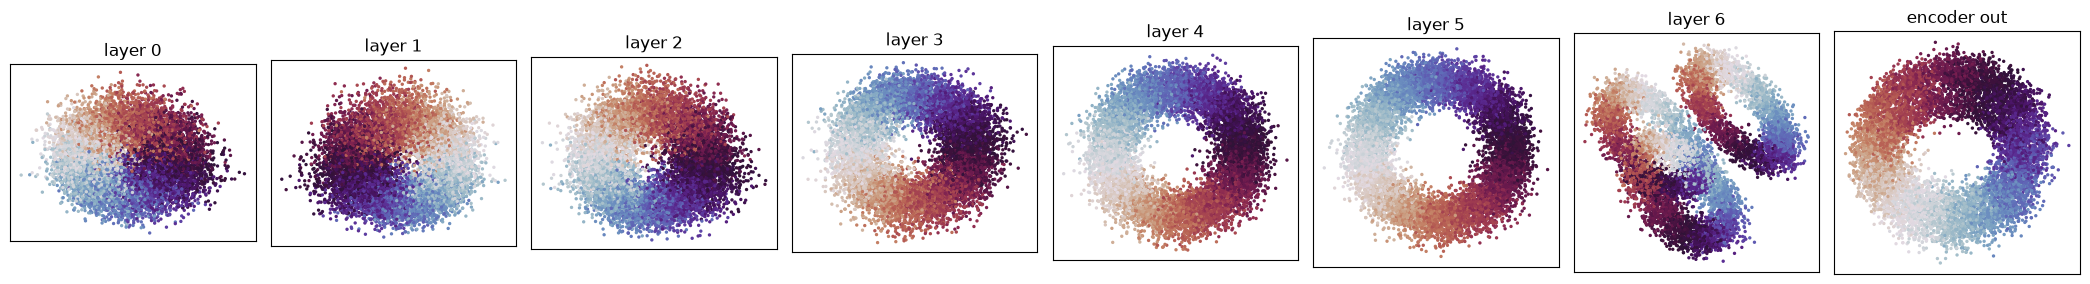

In [16]:
idx = 4

fig, axes = plt.subplots(1, 8, figsize=(21, 3.2))
for ax, (name, a) in zip(axes, acts.items()):
    X = a[:, :32].reshape(-1, 512)
    P = PCA(n_components=3).fit_transform(X)
    ax.scatter(P[:, 0], P[:, 1], c=y, cmap="twilight", s=2, vmin=0, vmax=2*np.pi)
    ax.set_aspect("equal")
    ax.set_title(name)
    ax.set_xticks([]); ax.set_yticks([])
plt.tight_layout()
plt.show()

## B - How much of this is trivial?

In [9]:
raw = {}

def grab_inputs(module, inputs, output):
    raw["patches"] = inputs[0].detach()

h = model.input_patch_embedding.register_forward_hook(grab_inputs)

try:
    with torch.no_grad():
        model(context)
finally:
    h.remove()

values = raw["patches"][:, :, :16]
print(values.shape)

torch.Size([300, 32, 16])


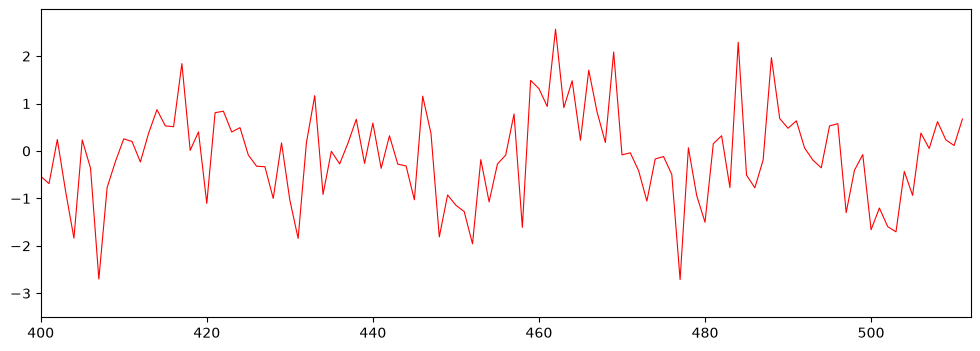

In [10]:
idx = 0
series = values[idx].reshape(-1)
fig, ax = plt.subplots(figsize=(12, 4))
ax.plot(t[:T], series, color="red", lw=0.8)
ax.set_xlim(400, T)
plt.show()

In [11]:
X = values.reshape(-1, 16)
P = PCA(n_components=2).fit_transform(X)

/tmp/ipykernel_2365/324242606.py:2: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap' will be ignored
  ax.scatter(P[:, 0], P[:, 1], cmap="twilight", s=2)


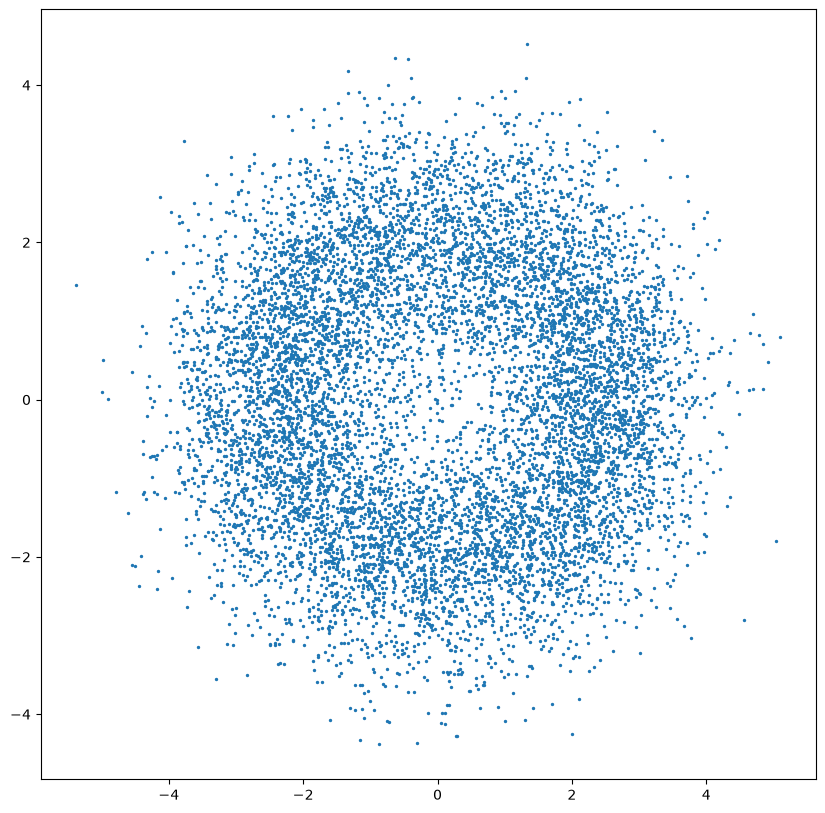

In [12]:
fig, ax = plt.subplots(figsize=(10, 10))
ax.scatter(P[:, 0], P[:, 1], cmap="twilight", s=2)
plt.show()

In [13]:
values_2d = values.reshape(300, 512, 2)


RuntimeError: shape '[300, 512, 2]' is invalid for input of size 153600

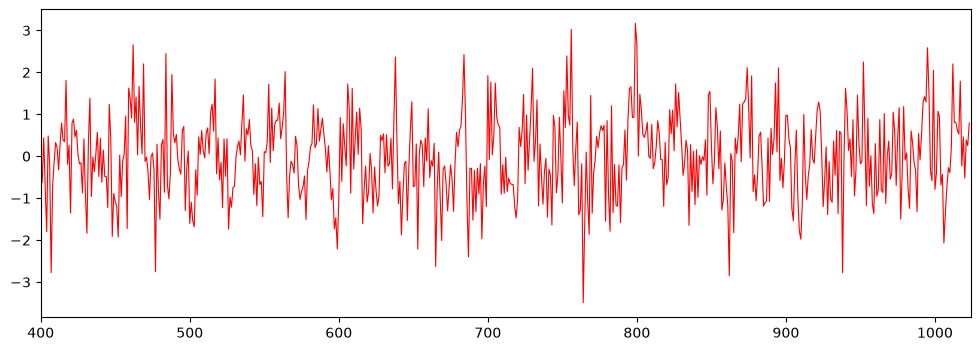

In [ ]:
idx = 0
series = values_2d[idx].reshape(-1)
fig, ax = plt.subplots(figsize=(12, 4))
ax.plot(t[:T], series, color="red", lw=0.8)
ax.set_xlim(400, T)
plt.show()

In [ ]:
X = values.reshape(-1, 2)
P = PCA(n_components=2).fit_transform(X)

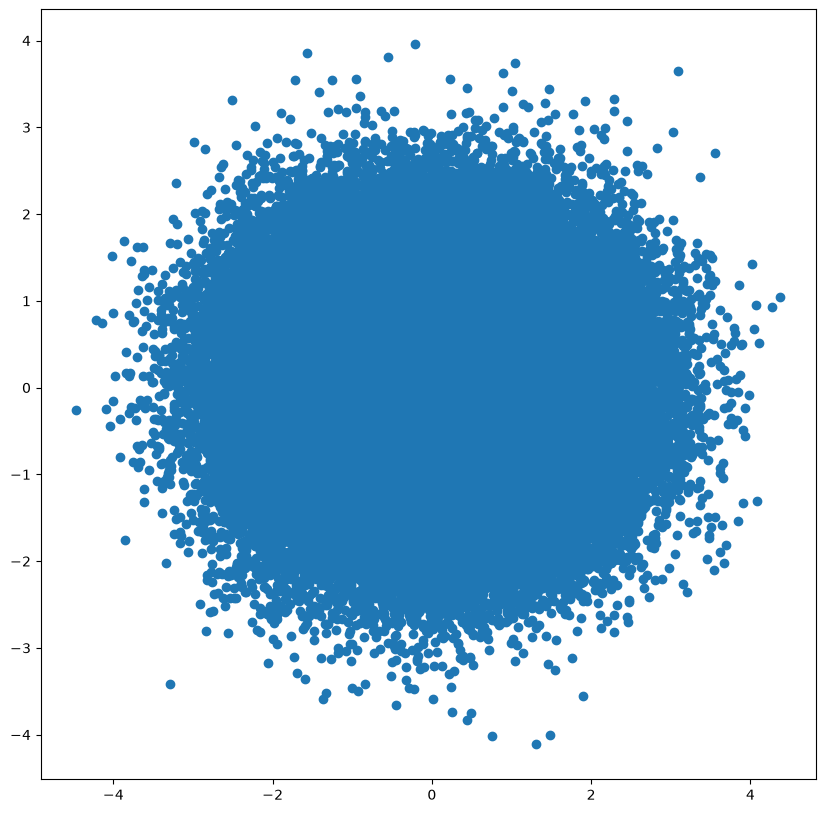

In [ ]:
fig, ax = plt.subplots(figsize=(10, 10))
ax.scatter(P[:, 0], P[:, 1])
plt.show()

In [20]:
rng.uniform(0, 2*np.pi, (n,1))

array([[4.94166184],
       [3.97195343],
       [5.35087074],
       [3.44499828],
       [1.52013651],
       [1.09180271],
       [4.94284622],
       [4.22060357],
       [4.4292203 ],
       [2.05924094],
       [3.21856102],
       [4.67275365],
       [5.08340684],
       [0.28969371],
       [3.32376624],
       [0.40292884],
       [3.69449546],
       [0.36150024],
       [2.10549478],
       [5.96567627],
       [1.20004098],
       [6.26502765],
       [2.72118068],
       [3.46953127],
       [1.75705605],
       [2.87724572],
       [4.11038378],
       [4.12217004],
       [3.62427532],
       [4.90659666],
       [4.7008296 ],
       [3.44439861],
       [2.25019647],
       [4.97440131],
       [2.48943619],
       [3.97153662],
       [2.80117213],
       [5.13948552],
       [1.52806735],
       [3.42941017],
       [3.59323484],
       [0.34507341],
       [3.90257805],
       [2.37083044],
       [4.2180693 ],
       [2.63884779],
       [1.31876017],
       [5.251